# Feature EDA
Examine the relationship between actual observed weather and same-day ridership.

**Sections:**
1. Setup
2. Weather overview
3. Historical vs forecast comparison (forecast quality check)
4. Weather x ridership correlations
5. Temperature effect
6. Rain effect
7. Snow effect
8. Wind effect

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client
from divvy_demand.utils import compare_ts, error_metrics

load_dotenv("../../.env")
s3 = S3Client(env="prod")

overall = s3.read_processed("overall")
overall["date"] = pd.to_datetime(overall["date"])
overall = overall.set_index("date").sort_index()

hist = s3.read_processed("weather/historical")
hist["date"] = pd.to_datetime(hist["date"])
hist = hist.set_index("date").sort_index()

fcst = s3.read_processed("weather/forecast")
fcst["date"] = pd.to_datetime(fcst["date"])
fcst = fcst.set_index("date").sort_index()

# Main analysis: actual rides + actual observed weather (same day)
df = overall.join(hist, how="left")

weather_vars = ["temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]

print("Shape:", df.shape)
df.head()

Shape: (2249, 8)


,total_rides,ebike_rides,member_rides,casual_rides,temp_min_c,rain_sum_mm,snowfall_sum_cm,wind_speed_max_kmh
date,,,,,,,,
2020-01-01,2141,0,1664,477,-6.1,0.0,0.00,35.7
2020-01-02,6479,0,5816,663,2.5,0.0,0.00,32.7
2020-01-03,5890,0,5437,453,0.2,0.0,0.00,13.4
2020-01-04,3187,0,2797,390,-2.0,0.0,1.40,21.8
2020-01-05,3035,0,2604,431,-4.8,0.0,0.07,36.0


## 2. Weather Overview

In [2]:
hist.describe()

,temp_min_c,rain_sum_mm,snowfall_sum_cm,wind_speed_max_kmh
count,2251.000000,2251.000000,2251.000000,2251.000000
mean,6.605820,2.620391,0.195571,24.164727
std,10.421102,6.880898,0.902370,7.950496
min,-24.900000,0.000000,0.000000,6.400000
25%,-1.000000,0.000000,0.000000,18.350000
50%,6.500000,0.000000,0.000000,23.200000
75%,16.200000,1.500000,0.000000,29.000000
max,25.900000,137.800000,11.760000,54.600000


In [3]:
hist.isnull().sum()

temp_min_c            0
rain_sum_mm           0
snowfall_sum_cm       0
wind_speed_max_kmh    0
dtype: int64

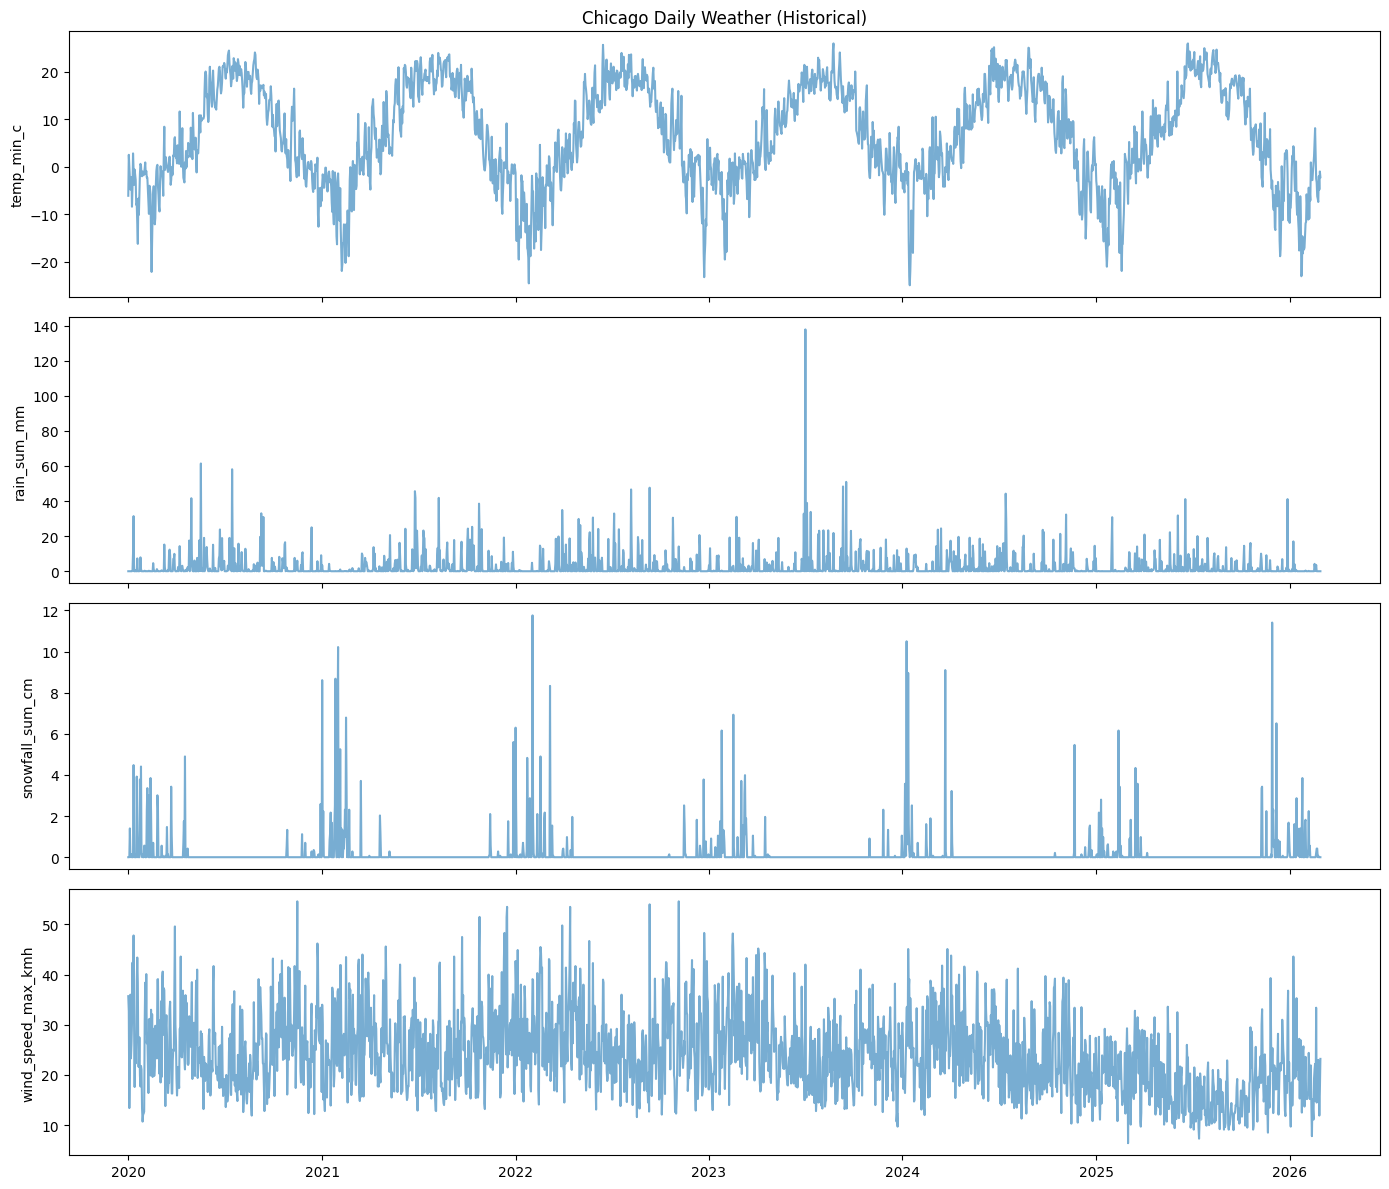

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, col in zip(axes, ["temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]):
    ax.plot(hist.index, hist[col], alpha=0.6)
    ax.set_ylabel(col)
axes[0].set_title("Chicago Daily Weather (Historical)")
plt.tight_layout()
plt.show()

## 3. Historical vs Forecast Comparison

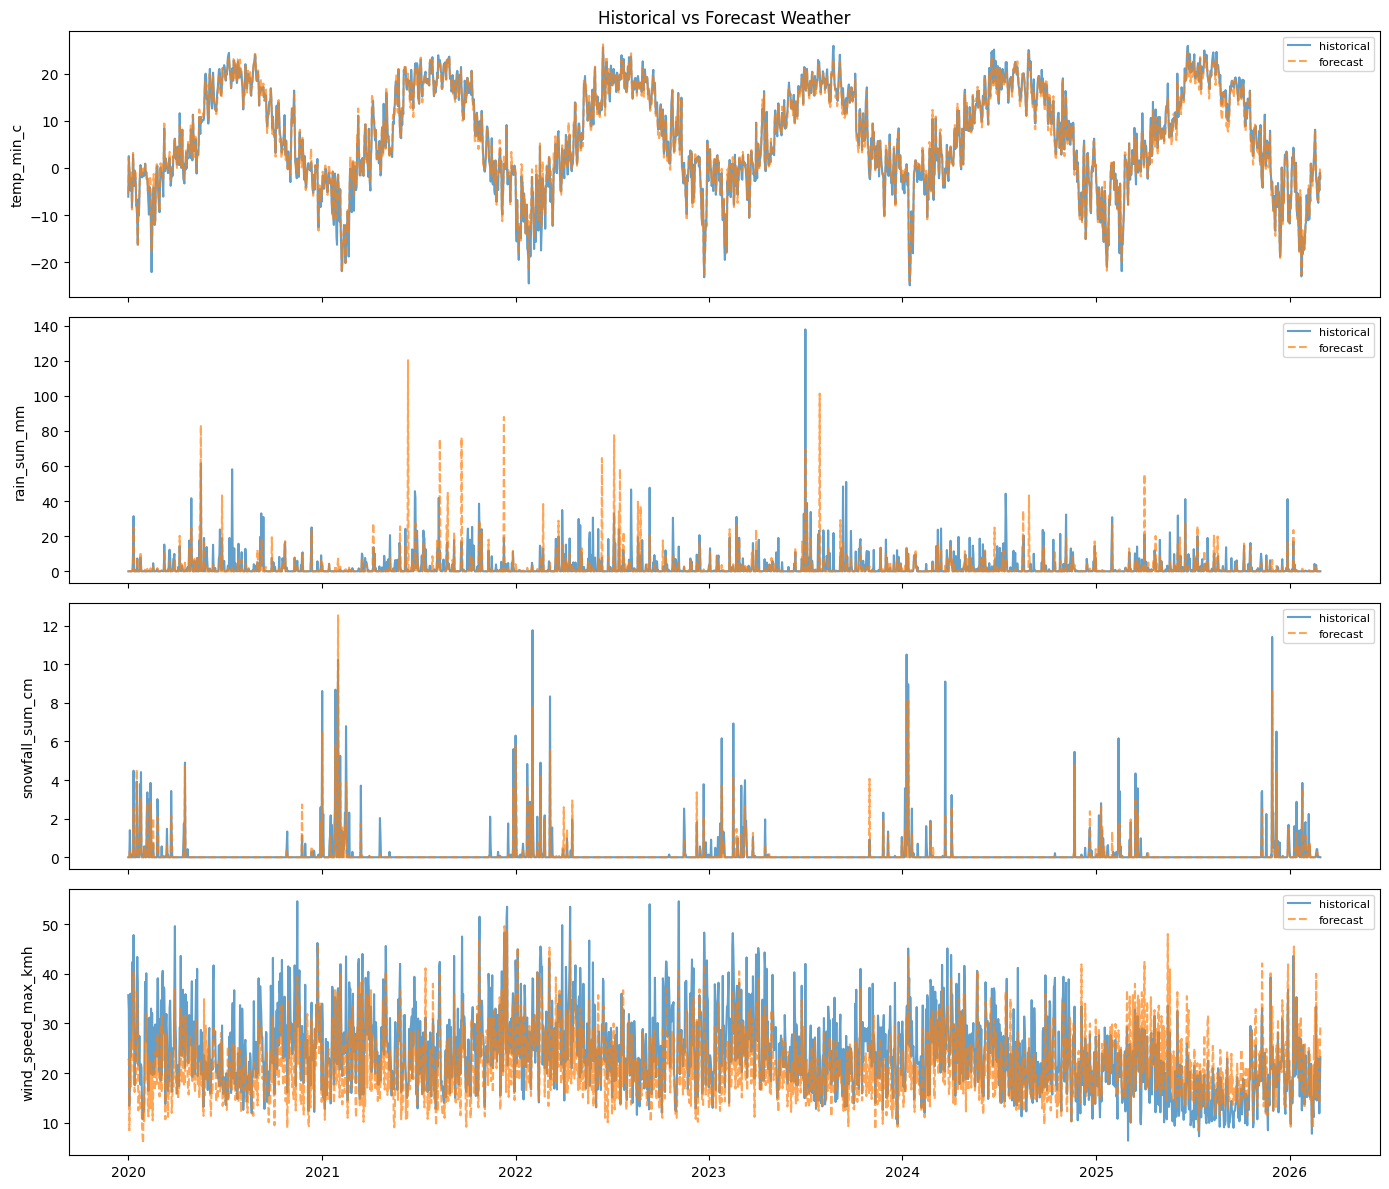

In [5]:
weather_vars = ["temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]
common_dates = hist.index.intersection(fcst.index)

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, col in zip(axes, weather_vars):
    ax.plot(common_dates, hist.loc[common_dates, col], label="historical", alpha=0.7)
    ax.plot(common_dates, fcst.loc[common_dates, col], label="forecast", linestyle="--", alpha=0.7)
    ax.set_ylabel(col)
    ax.legend(fontsize=8)
axes[0].set_title("Historical vs Forecast Weather")
plt.tight_layout()
plt.show()

In [6]:
# Error metrics per variable
from divvy_demand.utils import error_metrics

for col in weather_vars:
    h = hist.loc[common_dates, col].dropna()
    f = fcst.loc[common_dates, col].dropna()
    idx = h.index.intersection(f.index)
    m = error_metrics(h.loc[idx], f.loc[idx])
    print(f"{col:30s}  MAE={m['MAE']:.3f}  R²={m['R2']:.3f}  sMAPE={m['sMAPE']:.3f}")

temp_min_c                      MAE=0.910  R²=0.986  sMAPE=0.274
rain_sum_mm                     MAE=2.112  R²=-0.007  sMAPE=0.685
snowfall_sum_cm                 MAE=0.093  R²=0.808  sMAPE=0.161
wind_speed_max_kmh              MAE=4.756  R²=0.456  sMAPE=0.211


## 4. Weather x Ridership Correlations

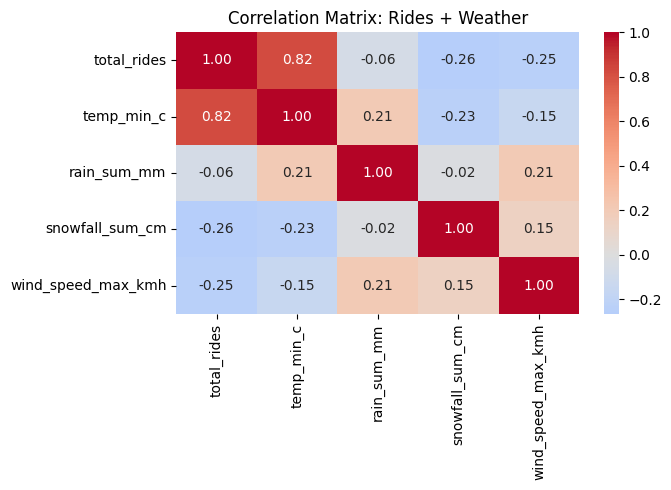

In [7]:
corr = df[["total_rides"] + weather_vars].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix: Rides + Weather")
plt.tight_layout()
plt.show()

## 5. Temperature Effect

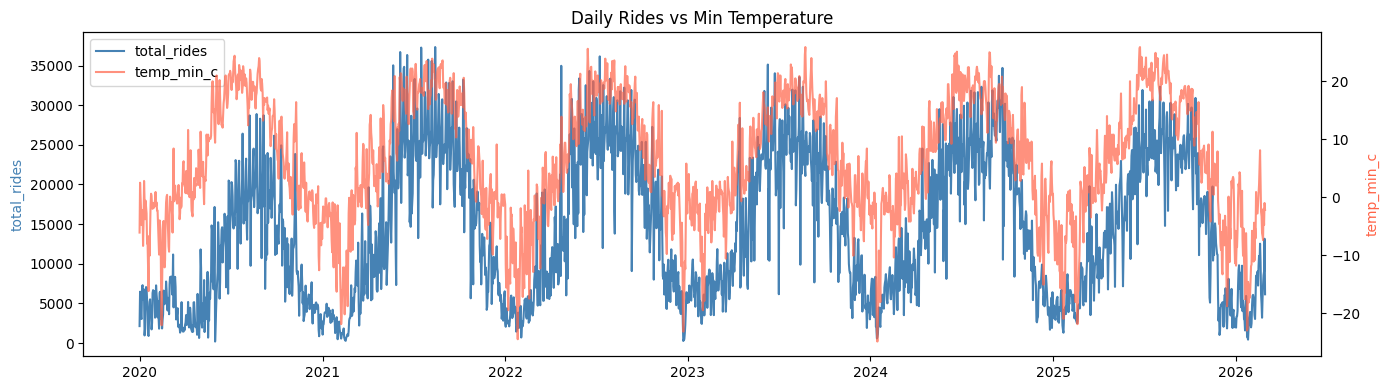

In [8]:
compare_ts(df, "total_rides", "temp_min_c", title="Daily Rides vs Min Temperature")

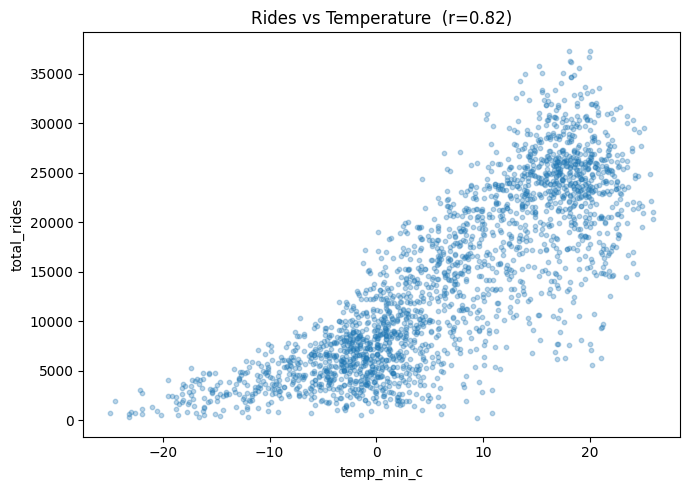

In [9]:
# Scatter
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["temp_min_c"], df["total_rides"], alpha=0.3, s=10)
ax.set_xlabel("temp_min_c")
ax.set_ylabel("total_rides")
ax.set_title(f"Rides vs Temperature  (r={df['total_rides'].corr(df['temp_min_c']):.2f})")
plt.tight_layout()
plt.show()

## 6. Rain Effect

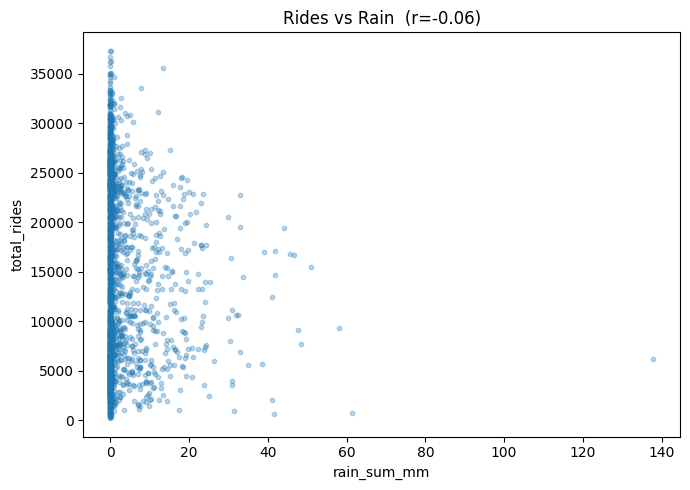

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["rain_sum_mm"], df["total_rides"], alpha=0.3, s=10)
ax.set_xlabel("rain_sum_mm")
ax.set_ylabel("total_rides")
ax.set_title(f"Rides vs Rain  (r={df['total_rides'].corr(df['rain_sum_mm']):.2f})")
plt.tight_layout()
plt.show()

Rainy mean: 14676  Dry mean: 14086  p=0.1148


/var/folders/pz/n51wnxpj59g9w6k9pl_ty57w0000gn/T/ipykernel_33674/3158501415.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([dry, rainy], labels=["No Rain", "Rain"])


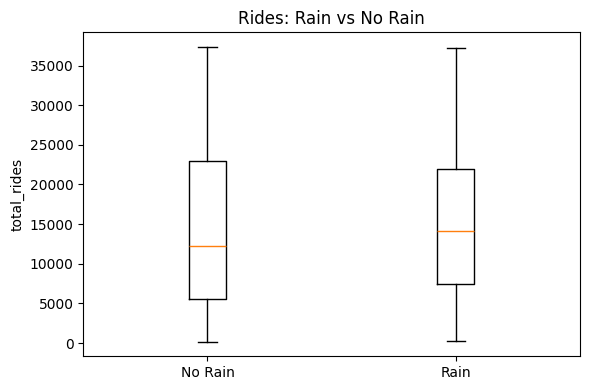

In [11]:
# Rainy vs non-rainy t-test
rainy = df[df["rain_sum_mm"] > 0]["total_rides"].dropna()
dry = df[df["rain_sum_mm"] == 0]["total_rides"].dropna()
t_stat, p_val = stats.ttest_ind(rainy, dry, equal_var=False)
print(f"Rainy mean: {rainy.mean():.0f}  Dry mean: {dry.mean():.0f}  p={p_val:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([dry, rainy], labels=["No Rain", "Rain"])
ax.set_title("Rides: Rain vs No Rain")
ax.set_ylabel("total_rides")
plt.tight_layout()
plt.show()

In [12]:
# Heavy rain (>= 75th percentile of rainy days)
q75 = df[df["rain_sum_mm"] > 0]["rain_sum_mm"].quantile(0.75)
print(f"Heavy rain threshold (Q75): {q75:.1f} mm")

heavy = df[df["rain_sum_mm"] >= q75]["total_rides"].dropna()
normal = df[df["rain_sum_mm"] < q75]["total_rides"].dropna()
t_stat, p_val = stats.ttest_ind(heavy, normal, equal_var=False)
print(f"Heavy rain mean: {heavy.mean():.0f}  Other mean: {normal.mean():.0f}  p={p_val:.4f}")

Heavy rain threshold (Q75): 7.6 mm
Heavy rain mean: 12957  Other mean: 14532  p=0.0021


## 7. Snow Effect

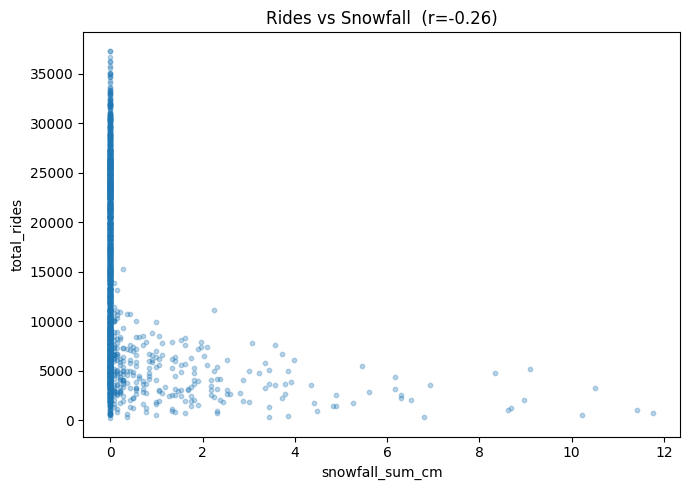

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["snowfall_sum_cm"], df["total_rides"], alpha=0.3, s=10)
ax.set_xlabel("snowfall_sum_cm")
ax.set_ylabel("total_rides")
ax.set_title(f"Rides vs Snowfall  (r={df['total_rides'].corr(df['snowfall_sum_cm']):.2f})")
plt.tight_layout()
plt.show()

Snowy mean: 4725  Clear mean: 15737  p=0.0000


/var/folders/pz/n51wnxpj59g9w6k9pl_ty57w0000gn/T/ipykernel_33674/3439654862.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([clear, snowy], labels=["No Snow", "Snow"])


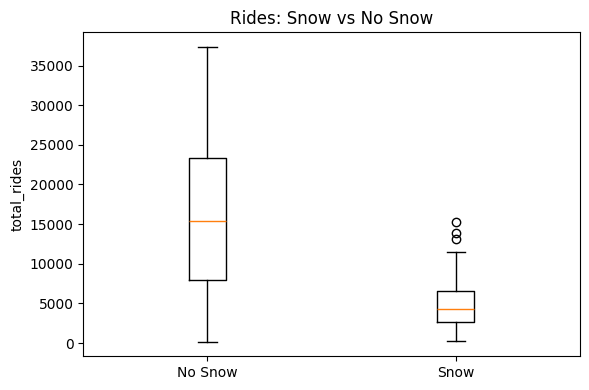

In [14]:
# Snowy vs non-snowy t-test
snowy = df[df["snowfall_sum_cm"] > 0]["total_rides"].dropna()
clear = df[df["snowfall_sum_cm"] == 0]["total_rides"].dropna()
t_stat, p_val = stats.ttest_ind(snowy, clear, equal_var=False)
print(f"Snowy mean: {snowy.mean():.0f}  Clear mean: {clear.mean():.0f}  p={p_val:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([clear, snowy], labels=["No Snow", "Snow"])
ax.set_title("Rides: Snow vs No Snow")
ax.set_ylabel("total_rides")
plt.tight_layout()
plt.show()

## 8. Wind Effect

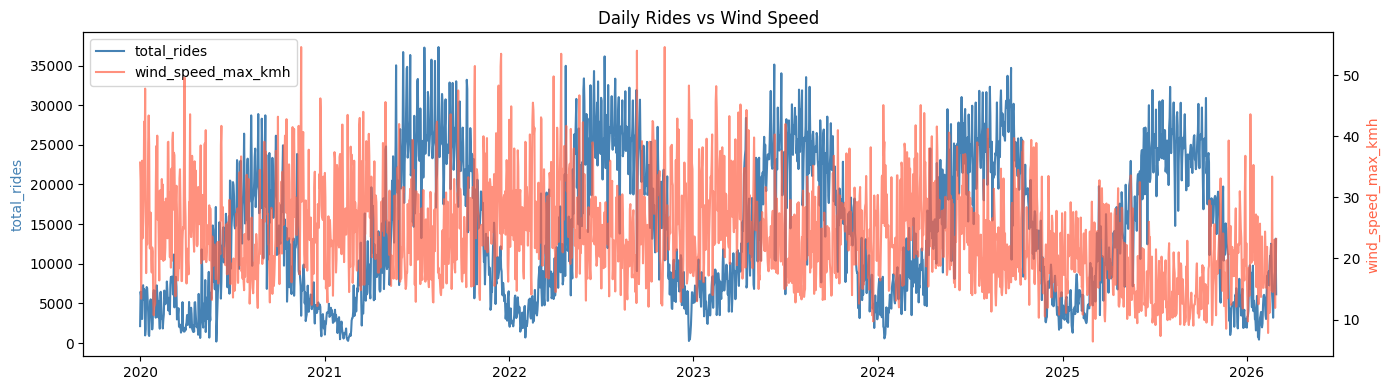

In [15]:
compare_ts(df, "total_rides", "wind_speed_max_kmh", title="Daily Rides vs Wind Speed")

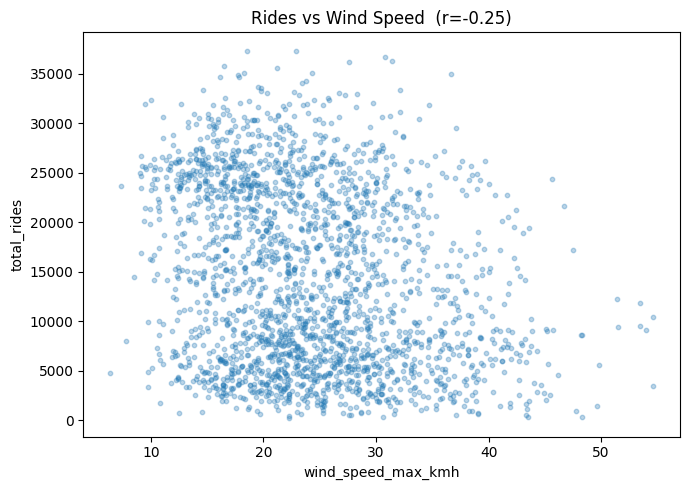

In [16]:
# Scatter + 30d MA
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["wind_speed_max_kmh"], df["total_rides"], alpha=0.3, s=10)
ax.set_xlabel("wind_speed_max_kmh")
ax.set_ylabel("total_rides")
ax.set_title(f"Rides vs Wind Speed  (r={df['total_rides'].corr(df['wind_speed_max_kmh']):.2f})")
plt.tight_layout()
plt.show()

## 9. E-bike & Ride-type EDA (Station-level)

Sample 5 stations and examine yearly rolling trends for e-bike counts and proportions.

In [17]:
# Load station-level data
station = s3.read_processed("station")
station["date"] = pd.to_datetime(station["date"])
station = station[station["start_station_name"] != "Outside of Dock"].copy()

# Filter to stations active on >95% of days
n_days = station["date"].nunique()
min_active_days = int(0.95 * n_days)
active_stations = (
    station.groupby("start_station_name")["date"]
    .nunique()
    .loc[lambda s: s > min_active_days]
    .index
)
station = station[station["start_station_name"].isin(active_stations)]

# Sample 5 stations (seed for reproducibility)
rng = np.random.default_rng(42)
sample_stations = rng.choice(active_stations, size=5, replace=False).tolist()
print("Sampled stations:", sample_stations)

sample = (
    station[station["start_station_name"].isin(sample_stations)]
    .sort_values(["start_station_name", "date"])
    .copy()
)

# Ebike proportion
sample["ebike_prop"] = sample["ebike_rides"] / sample["total_rides"].replace(0, np.nan)


Sampled stations: ['Sedgwick St & Schiller St', 'Halsted St & Roscoe St', 'Morgan St & 31st St', 'Broadway & Sheridan Rd', 'Halsted St & Polk St']


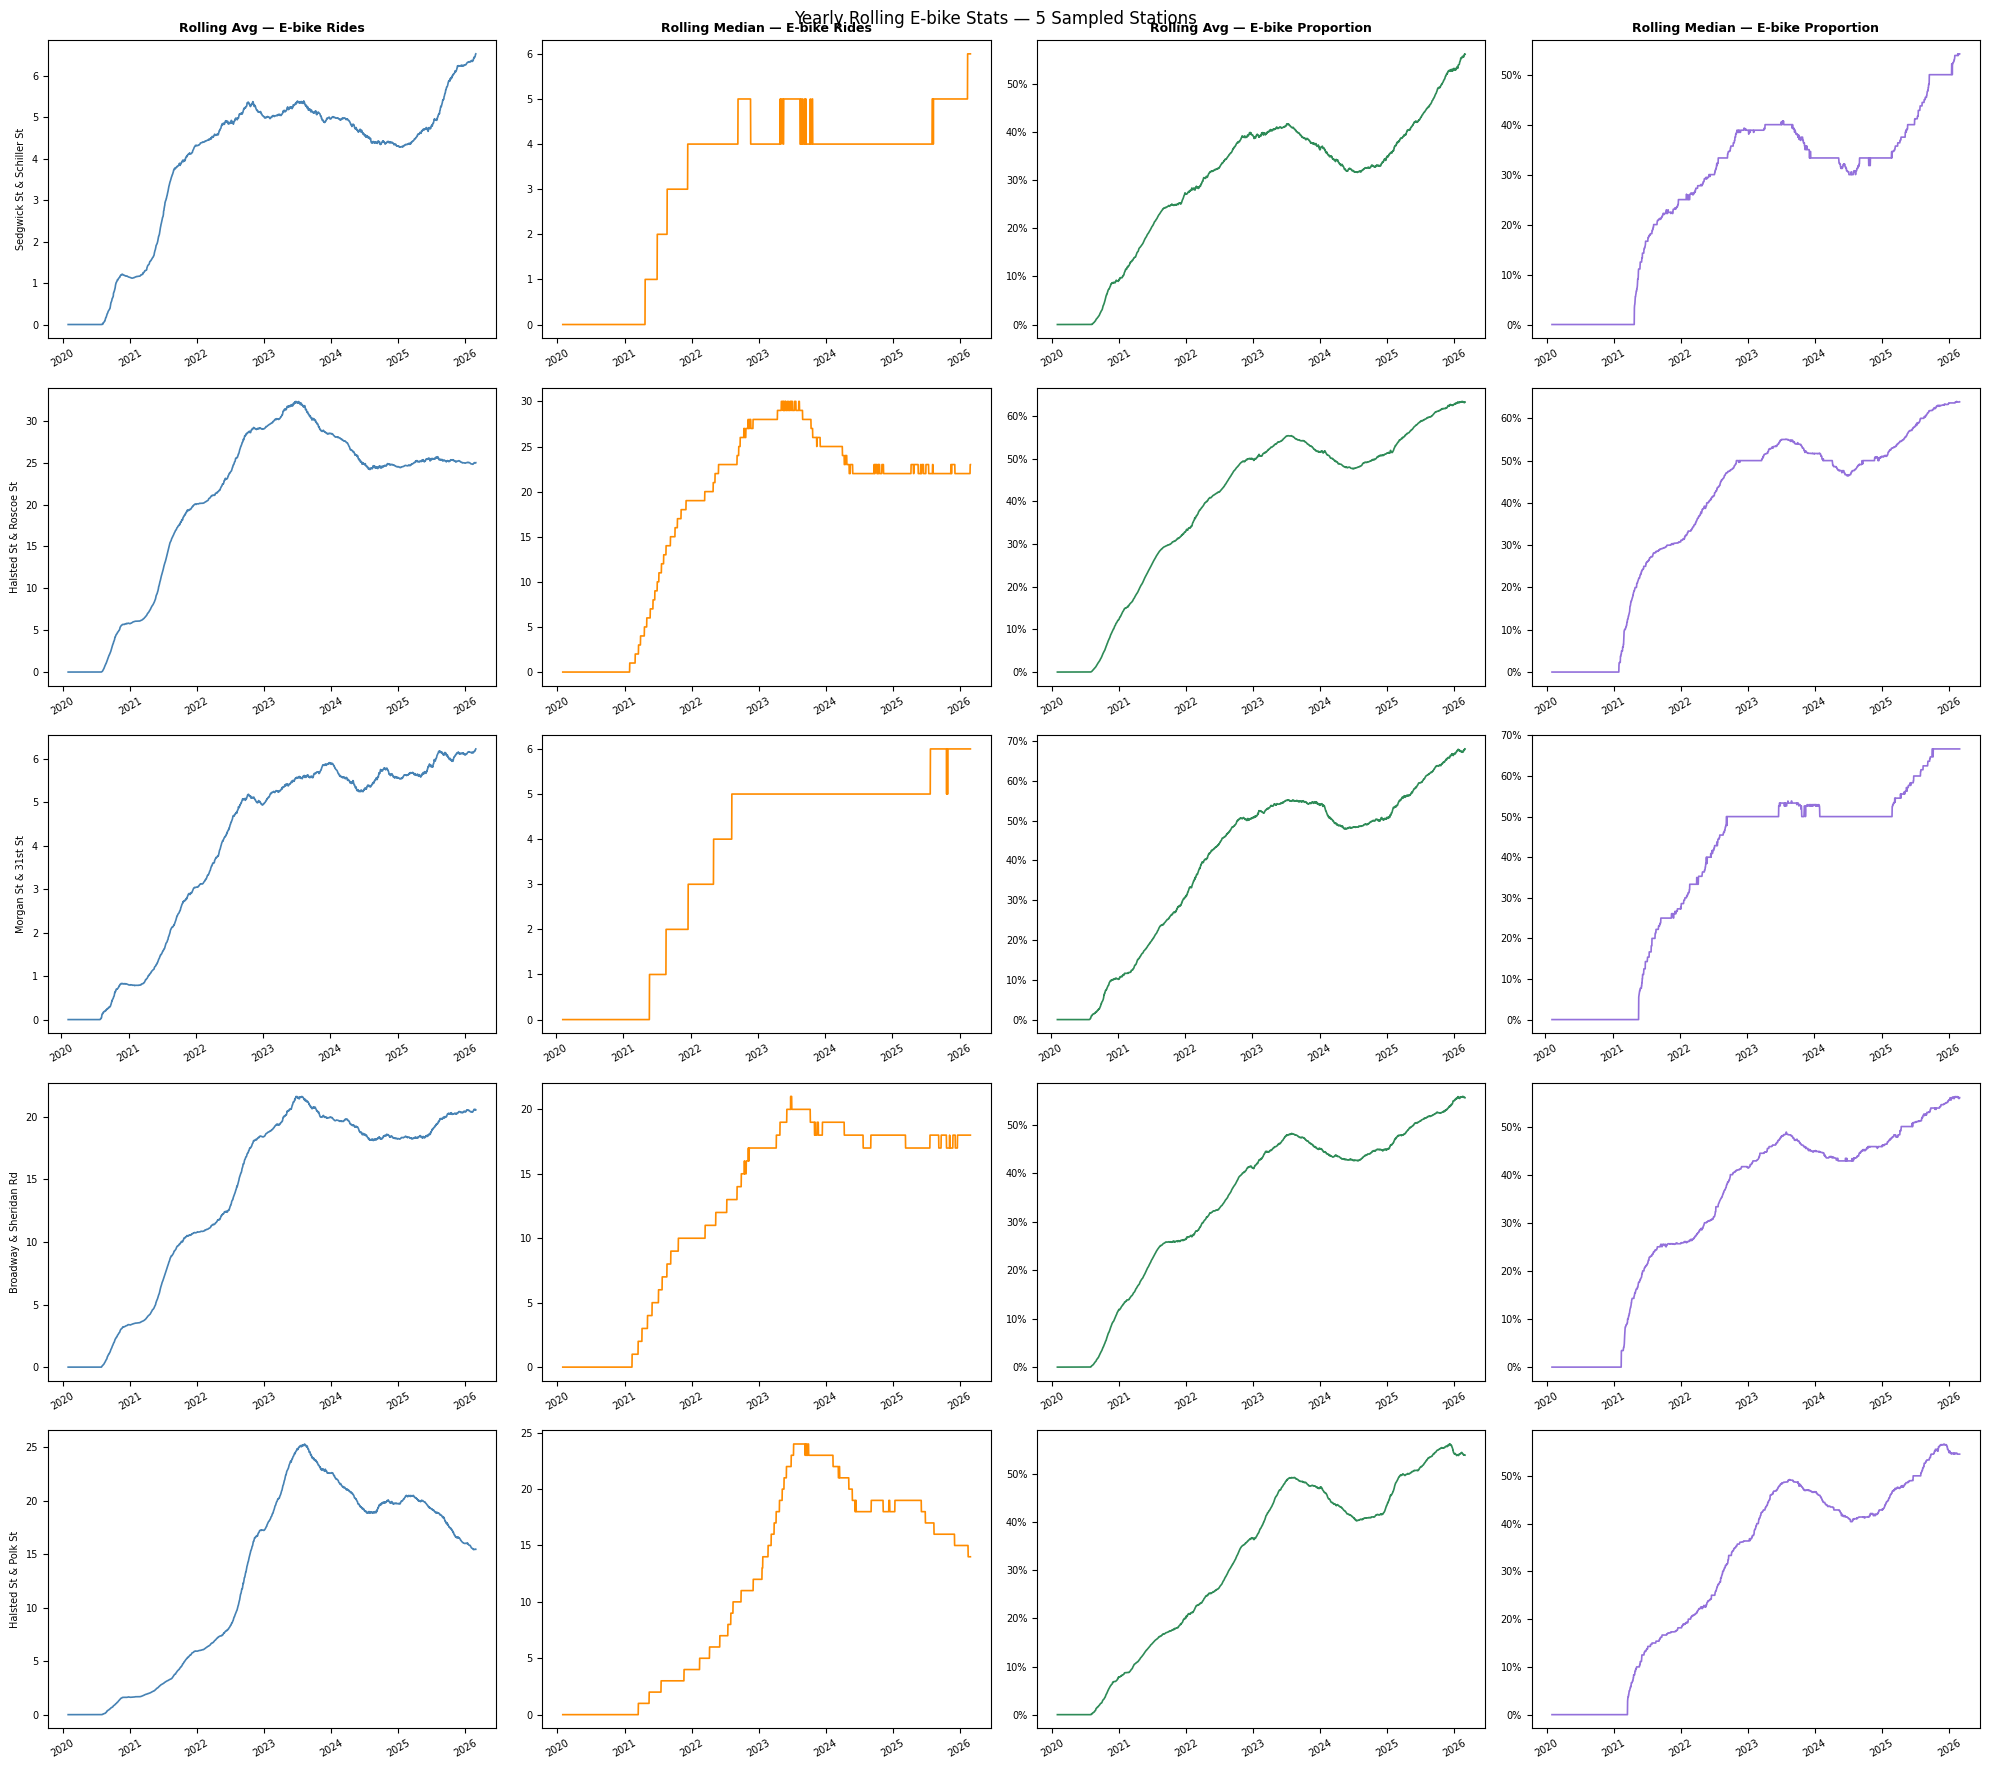

In [18]:
WINDOW = 365  # yearly rolling

fig, axes = plt.subplots(5, 4, figsize=(20, 18), sharex=False)
fig.suptitle("Yearly Rolling E-bike Stats — 5 Sampled Stations", fontsize=12)

col_titles = [
    "Rolling Avg — E-bike Rides",
    "Rolling Median — E-bike Rides",
    "Rolling Avg — E-bike Proportion",
    "Rolling Median — E-bike Proportion",
]
for ax, title in zip(axes[0], col_titles):
    ax.set_title(title, fontsize=9, fontweight="bold")

for row, name in enumerate(sample_stations):
    grp = sample[sample["start_station_name"] == name].set_index("date").sort_index()

    roll_mean_count  = grp["ebike_rides"].rolling(WINDOW, min_periods=30).mean()
    roll_med_count   = grp["ebike_rides"].rolling(WINDOW, min_periods=30).median()
    roll_mean_prop   = grp["ebike_prop"].rolling(WINDOW,  min_periods=30).mean()
    roll_med_prop    = grp["ebike_prop"].rolling(WINDOW,  min_periods=30).median()

    short_name = name[:35] + ("…" if len(name) > 35 else "")

    for col, (series, color) in enumerate([
        (roll_mean_count, "steelblue"),
        (roll_med_count,  "darkorange"),
        (roll_mean_prop,  "seagreen"),
        (roll_med_prop,   "mediumpurple"),
    ]):
        ax = axes[row, col]
        ax.plot(series.index, series.values, color=color, linewidth=1.2)
        ax.set_ylabel(short_name if col == 0 else "", fontsize=7)
        ax.tick_params(axis="x", labelsize=7, rotation=30)
        ax.tick_params(axis="y", labelsize=7)
        if col in [2, 3]:
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

plt.tight_layout()
plt.show()


## 10. Member vs Casual EDA (Station-level)

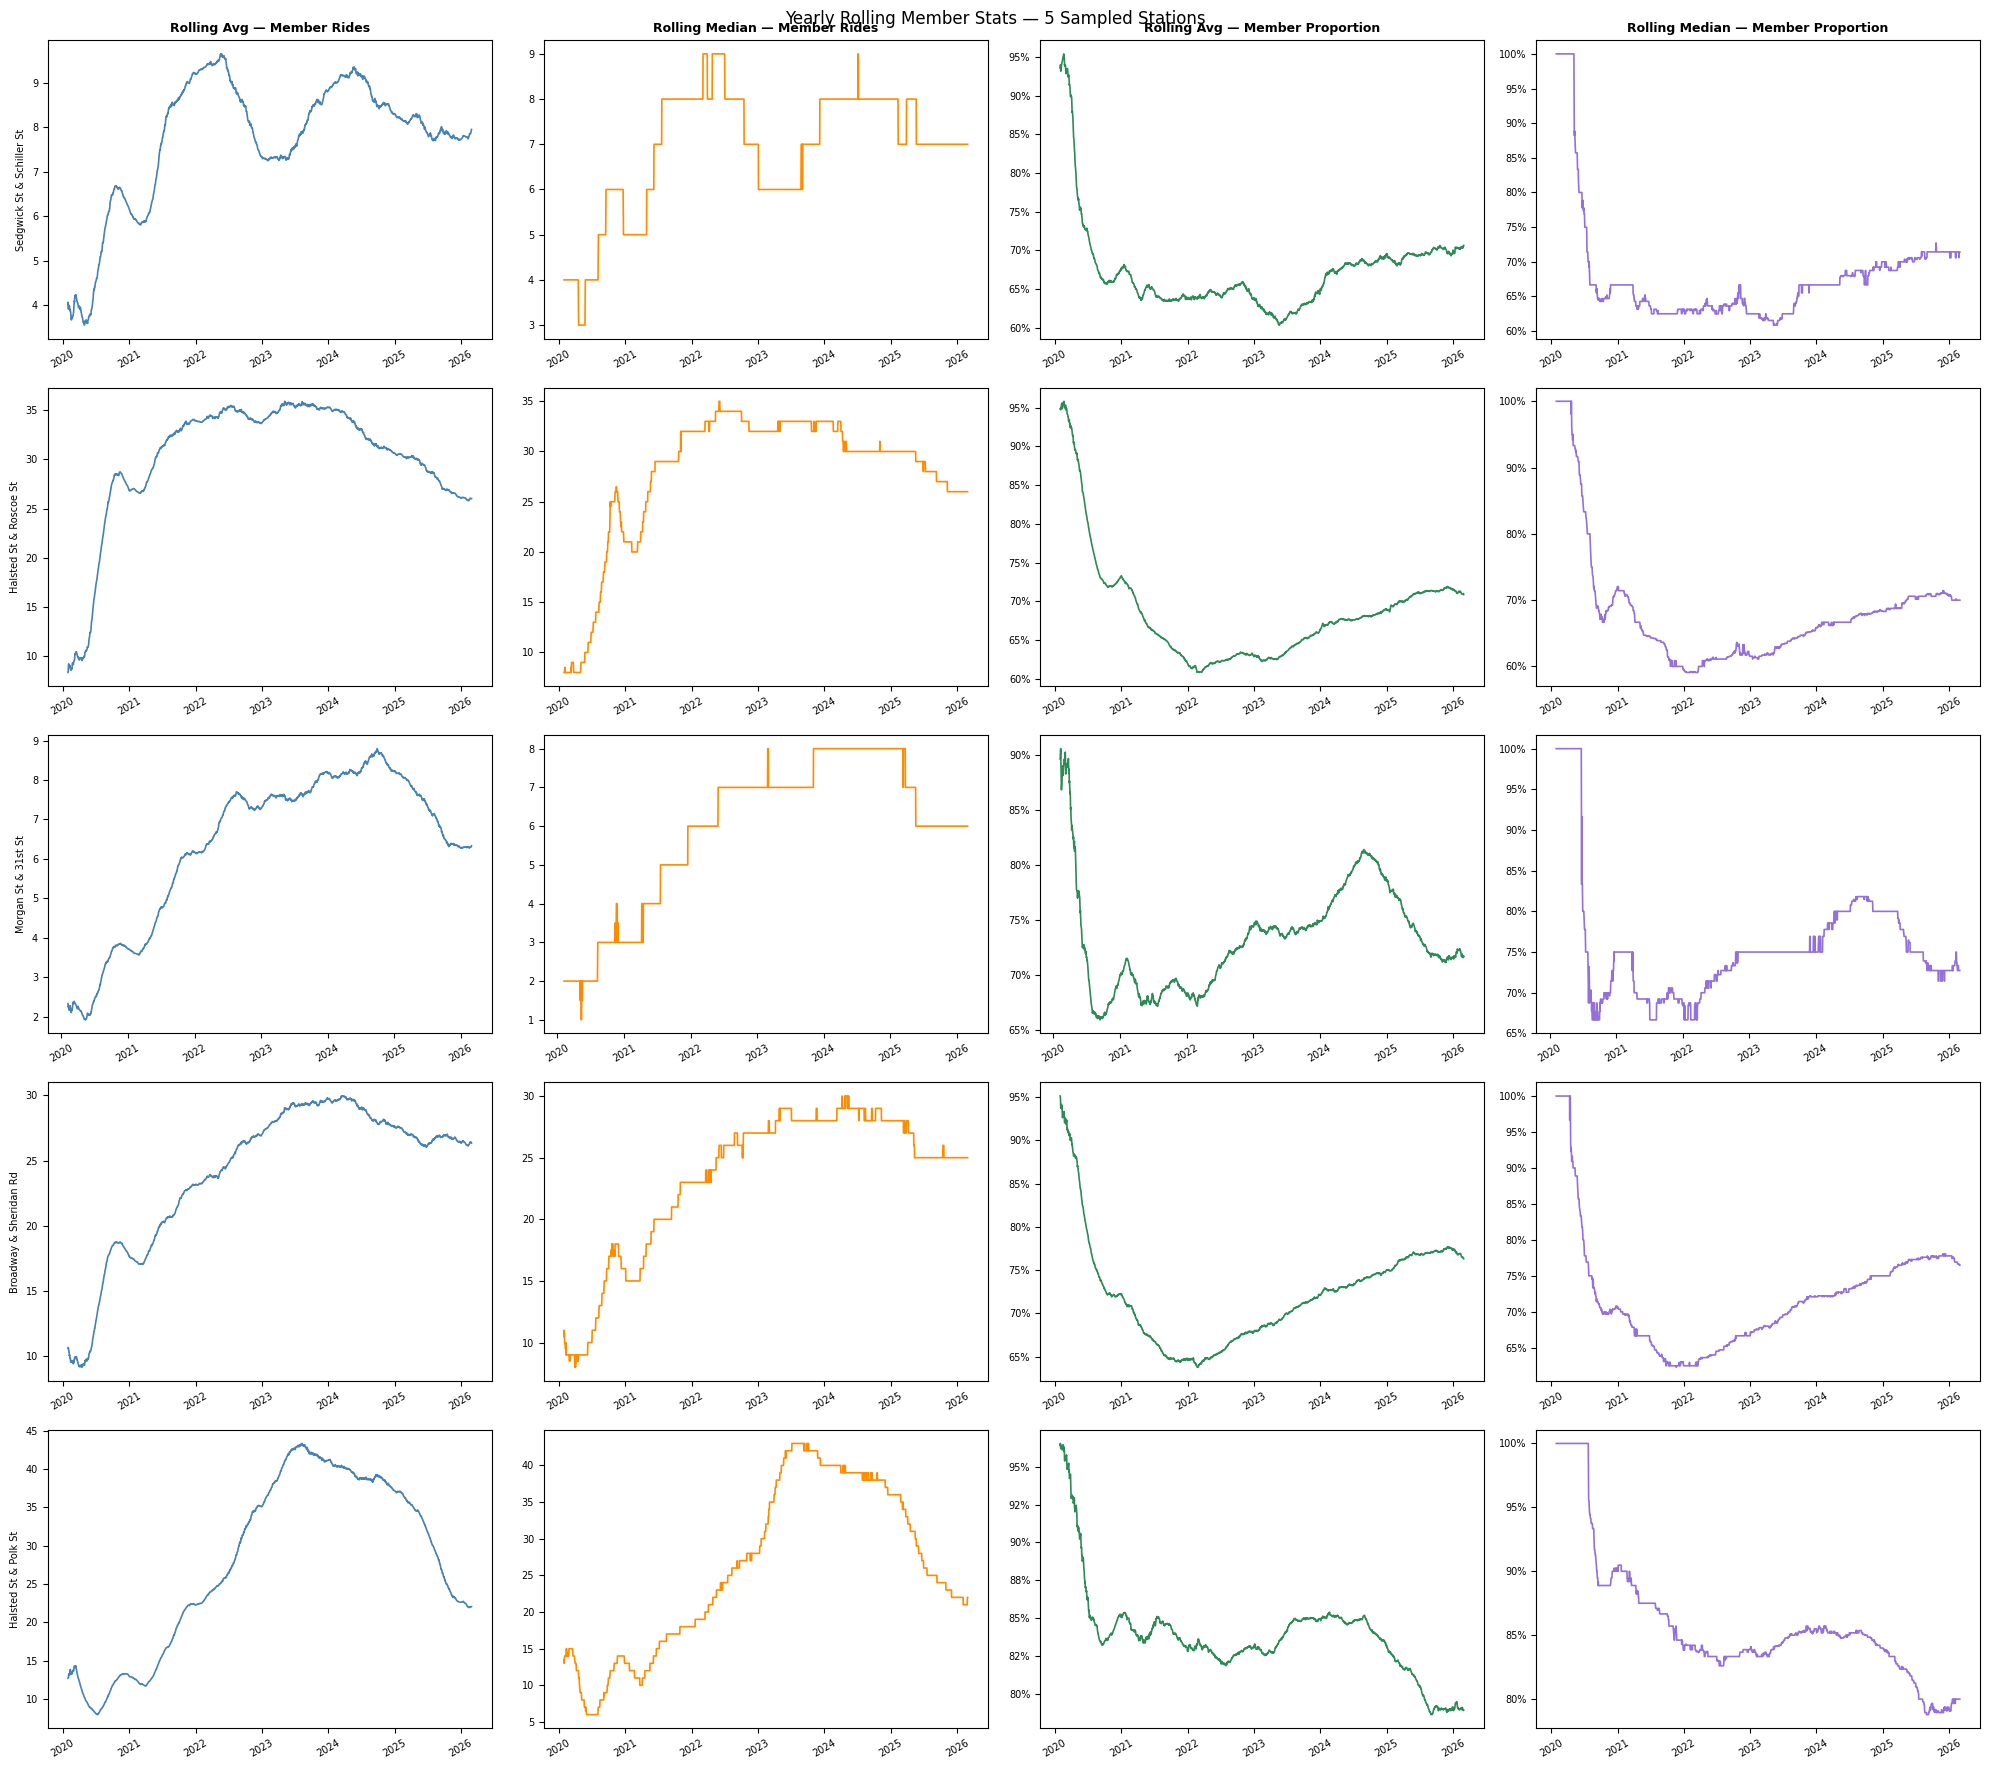

In [19]:
# Member proportion (reuse sample from section 9)
sample["member_prop"] = sample["member_rides"] / sample["total_rides"].replace(0, np.nan)

WINDOW = 365

fig, axes = plt.subplots(5, 4, figsize=(20, 18), sharex=False)
fig.suptitle("Yearly Rolling Member Stats — 5 Sampled Stations", fontsize=12)

col_titles = [
    "Rolling Avg — Member Rides",
    "Rolling Median — Member Rides",
    "Rolling Avg — Member Proportion",
    "Rolling Median — Member Proportion",
]
for ax, title in zip(axes[0], col_titles):
    ax.set_title(title, fontsize=9, fontweight="bold")

for row, name in enumerate(sample_stations):
    grp = sample[sample["start_station_name"] == name].set_index("date").sort_index()

    roll_mean_count = grp["member_rides"].rolling(WINDOW, min_periods=30).mean()
    roll_med_count  = grp["member_rides"].rolling(WINDOW, min_periods=30).median()
    roll_mean_prop  = grp["member_prop"].rolling(WINDOW,  min_periods=30).mean()
    roll_med_prop   = grp["member_prop"].rolling(WINDOW,  min_periods=30).median()

    short_name = name[:35] + ("…" if len(name) > 35 else "")

    for col, (series, color) in enumerate([
        (roll_mean_count, "steelblue"),
        (roll_med_count,  "darkorange"),
        (roll_mean_prop,  "seagreen"),
        (roll_med_prop,   "mediumpurple"),
    ]):
        ax = axes[row, col]
        ax.plot(series.index, series.values, color=color, linewidth=1.2)
        ax.set_ylabel(short_name if col == 0 else "", fontsize=7)
        ax.tick_params(axis="x", labelsize=7, rotation=30)
        ax.tick_params(axis="y", labelsize=7)
        if col in [2, 3]:
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

plt.tight_layout()
plt.show()


## 11. Differencing Strategy

Check stationarity and ACF/PACF for the original series and weekly-differenced series (lag=7) on overall citywide rides.

In [20]:
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def adf_report(series, label):
    s = series.dropna()
    result = adfuller(s, autolag='AIC')
    print(f"[{label}]")
    print(f"  ADF statistic : {result[0]:.4f}")
    print(f"  p-value       : {result[1]:.6f}")
    print(f"  Lags used     : {result[2]}")
    print(f"  Stationary    : {'YES' if result[1] < 0.05 else 'NO  <-- unit root likely'}")
    print()

series_orig = overall["total_rides"].dropna()
series_diff7 = series_orig.diff(1).diff(7).dropna()

adf_report(series_orig,  "Original")
adf_report(series_diff7, "Lag-1 then Weekly diff (1→7)")


[Original]
  ADF statistic : -2.5316
  p-value       : 0.107977
  Lags used     : 27
  Stationary    : NO  <-- unit root likely

[Lag-1 then Weekly diff (1→7)]
  ADF statistic : -16.6660
  p-value       : 0.000000
  Lags used     : 27
  Stationary    : YES



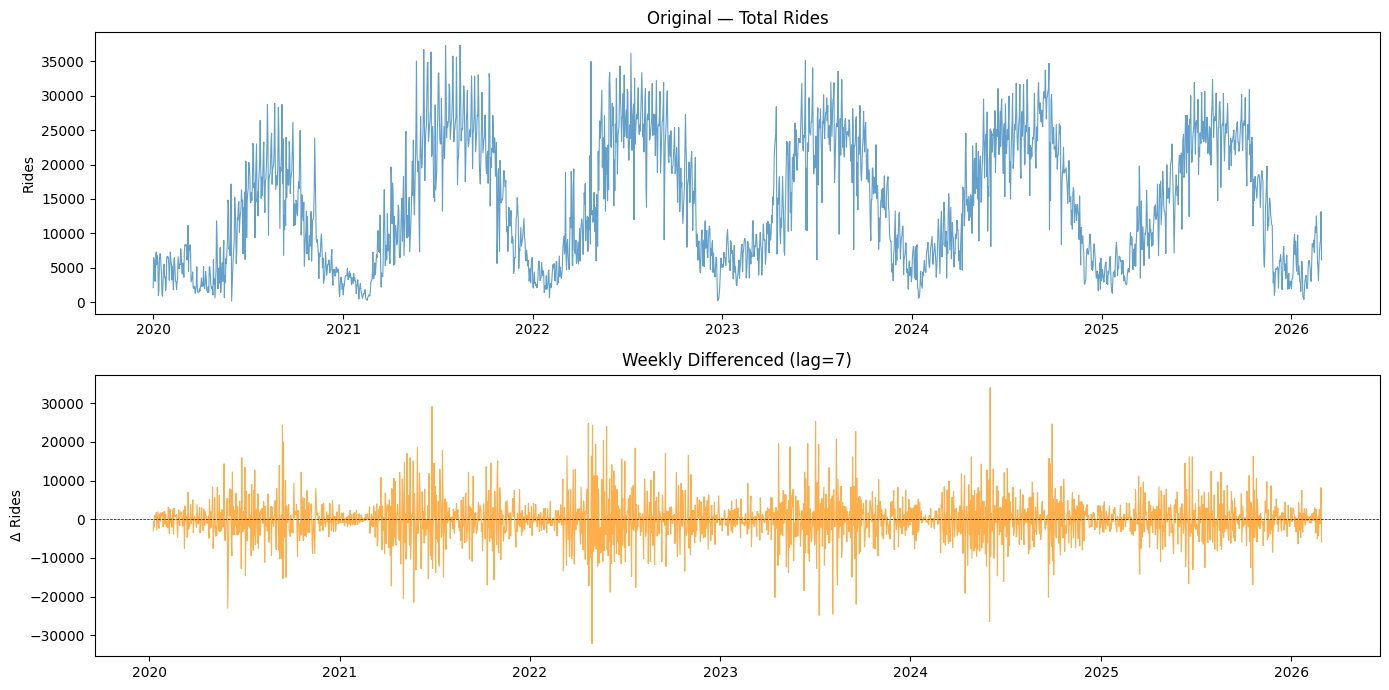

In [21]:
# Side-by-side: original vs weekly diff time series
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

axes[0].plot(series_orig.index, series_orig.values, alpha=0.7, linewidth=0.8)
axes[0].set_title("Original — Total Rides")
axes[0].set_ylabel("Rides")

axes[1].plot(series_diff7.index, series_diff7.values, alpha=0.7, linewidth=0.8, color="darkorange")
axes[1].axhline(0, color="black", linewidth=0.5, linestyle="--")
axes[1].set_title("Weekly Differenced (lag=7)")
axes[1].set_ylabel("Δ Rides")

plt.tight_layout()
plt.show()


### 11b. Lag-1 Difference

[Lag-1 diff]
  ADF statistic : -9.8400
  p-value       : 0.000000
  Lags used     : 27
  Stationary    : YES



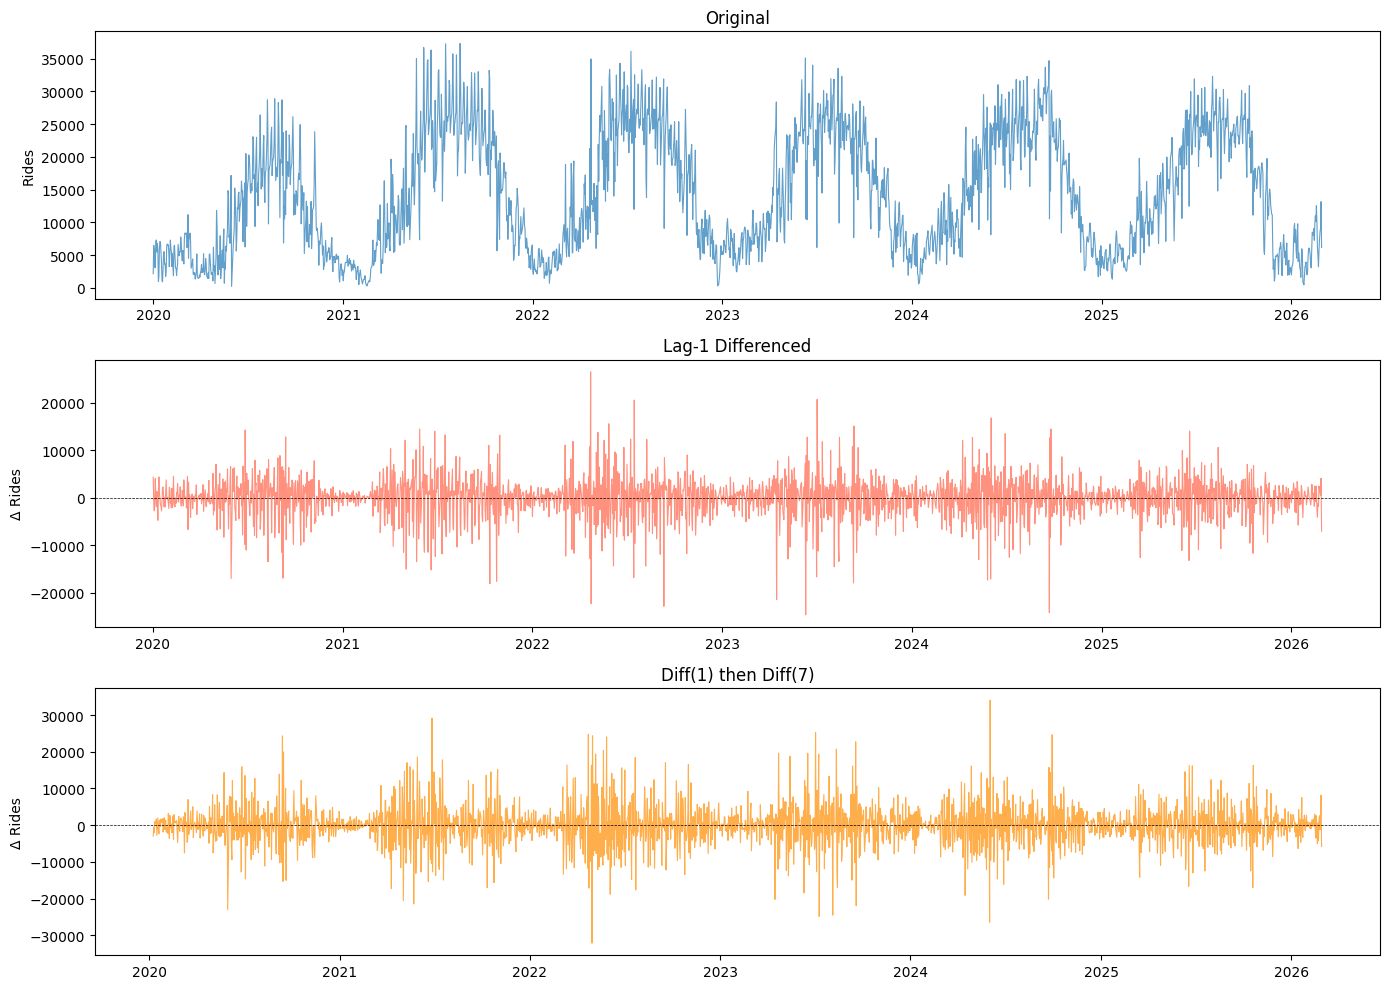

In [22]:
series_diff1 = series_orig.diff(1).dropna()
adf_report(series_diff1, "Lag-1 diff")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)

axes[0].plot(series_orig.index,   series_orig.values,   alpha=0.7, linewidth=0.8, label="Original")
axes[0].set_title("Original"); axes[0].set_ylabel("Rides")

axes[1].plot(series_diff1.index,  series_diff1.values,  alpha=0.7, linewidth=0.8, color="tomato", label="Diff(1)")
axes[1].axhline(0, color="black", linewidth=0.5, linestyle="--")
axes[1].set_title("Lag-1 Differenced"); axes[1].set_ylabel("Δ Rides")

axes[2].plot(series_diff7.index,  series_diff7.values,  alpha=0.7, linewidth=0.8, color="darkorange", label="Diff(7)")
axes[2].axhline(0, color="black", linewidth=0.5, linestyle="--")
axes[2].set_title("Diff(1) then Diff(7)"); axes[2].set_ylabel("Δ Rides")

plt.tight_layout()
plt.show()


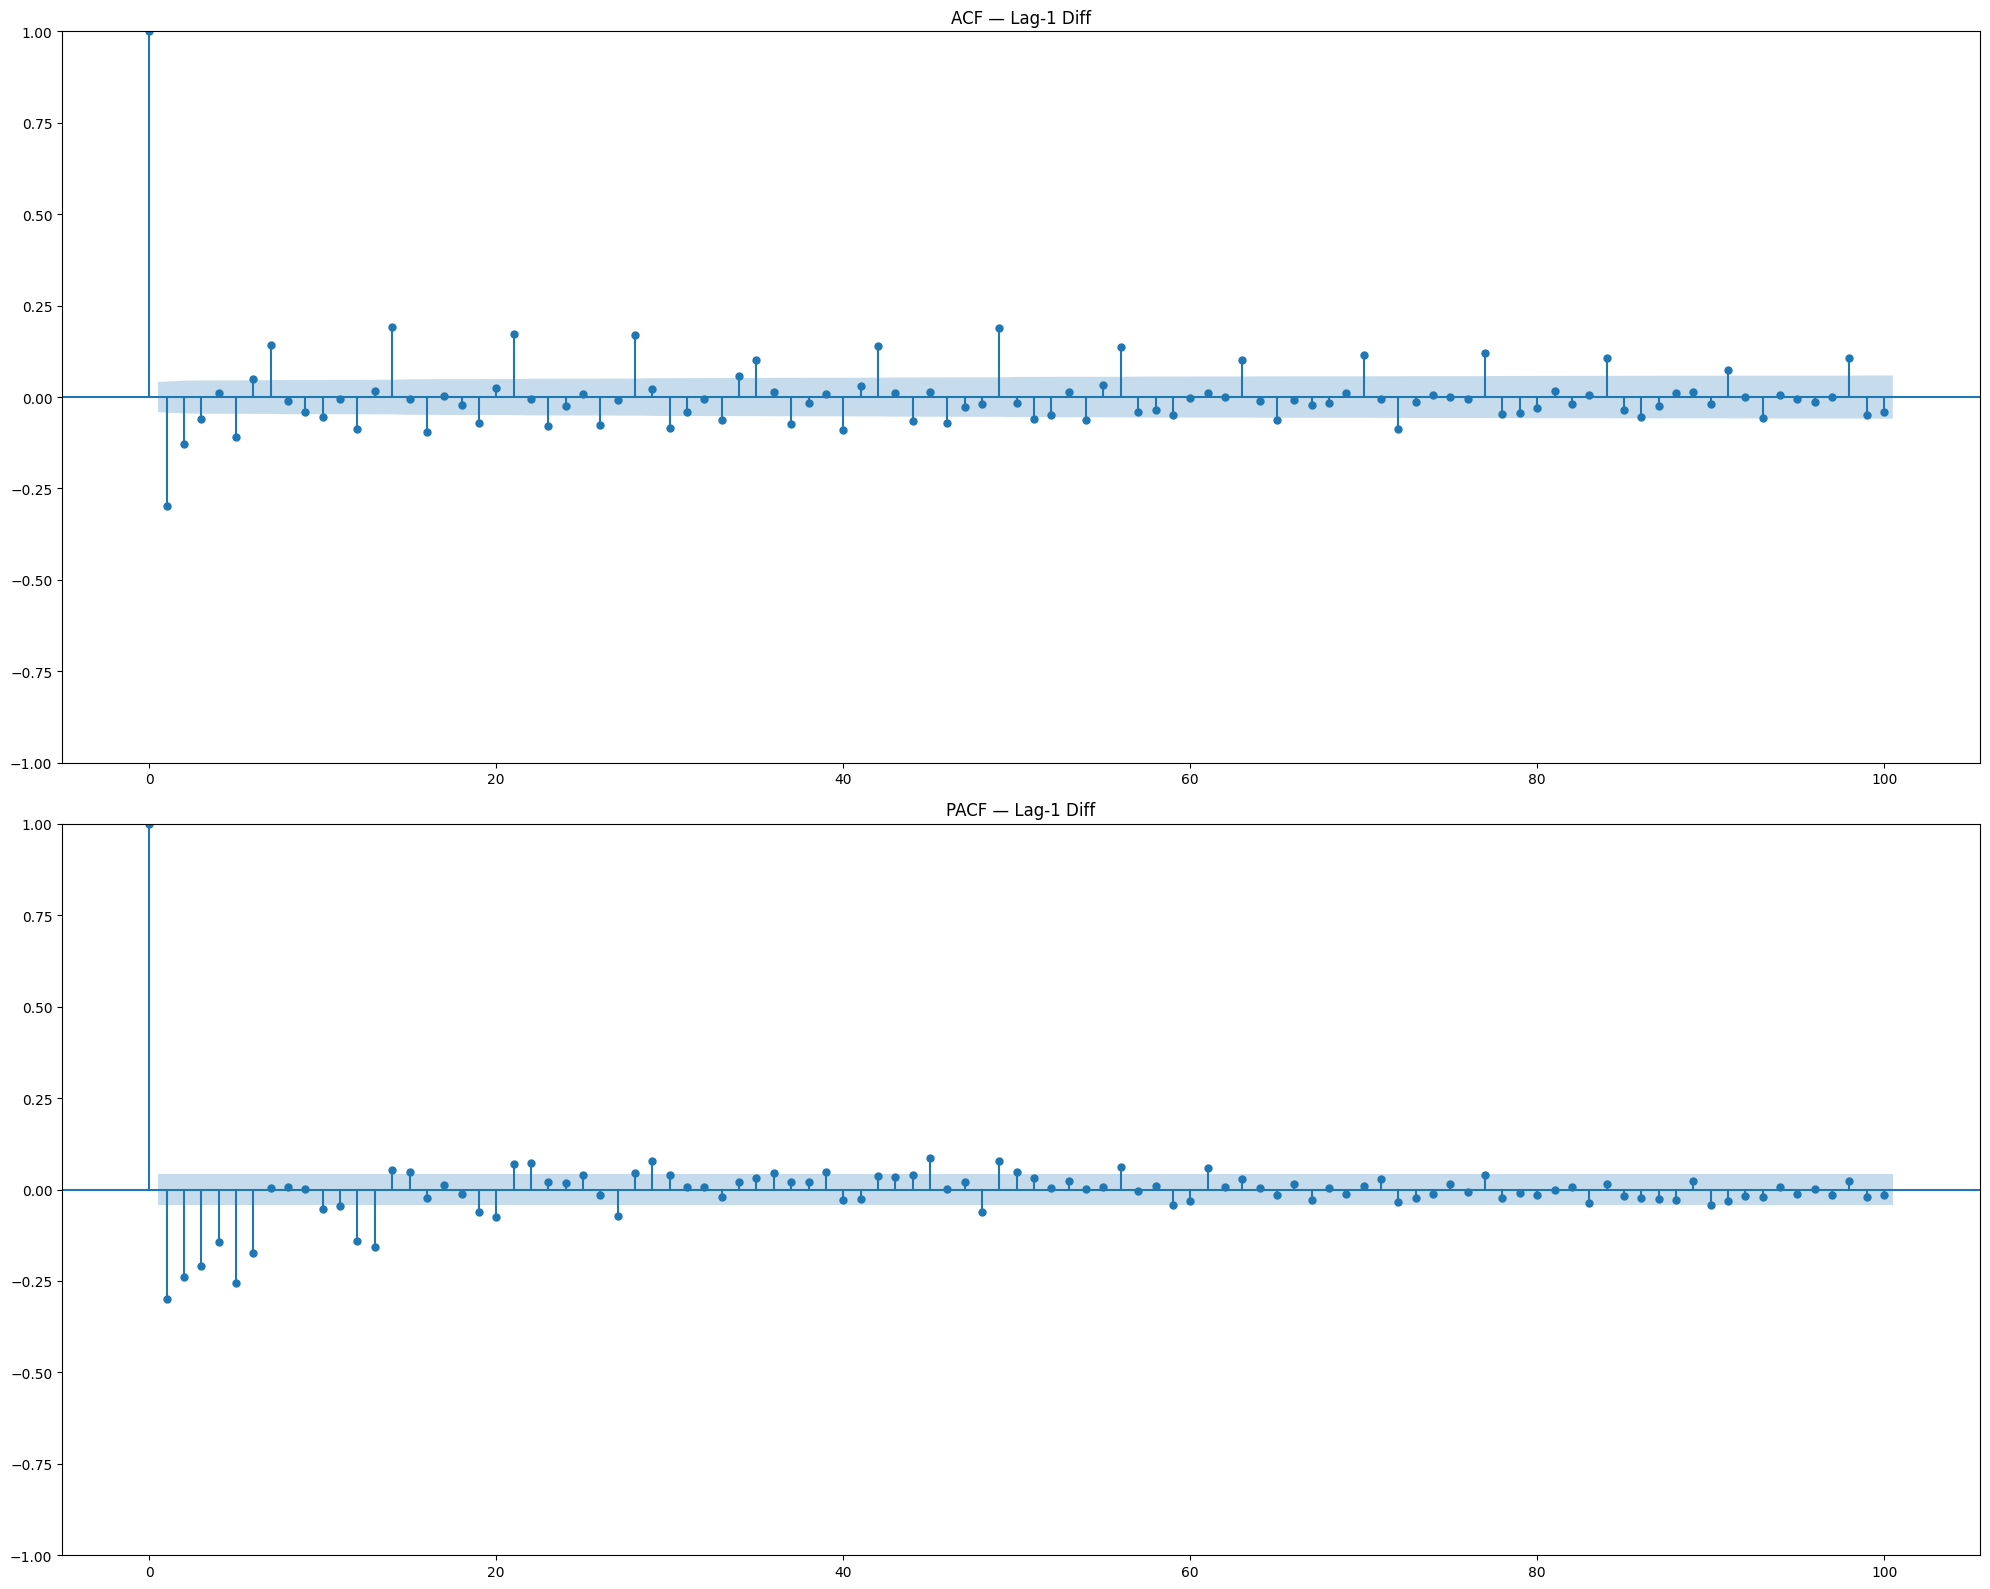

In [23]:
LAGS = 100

# ACF / PACF — lag-1 diff
fig, axes = plt.subplots(2, 1, figsize=(20, 16))
plot_acf( series_diff1, lags=LAGS, ax=axes[0], alpha=0.05)
plot_pacf(series_diff1, lags=LAGS, ax=axes[1], alpha=0.05, method='ywm')
axes[0].set_title("ACF — Lag-1 Diff")
axes[1].set_title("PACF — Lag-1 Diff")
plt.tight_layout()
plt.show()


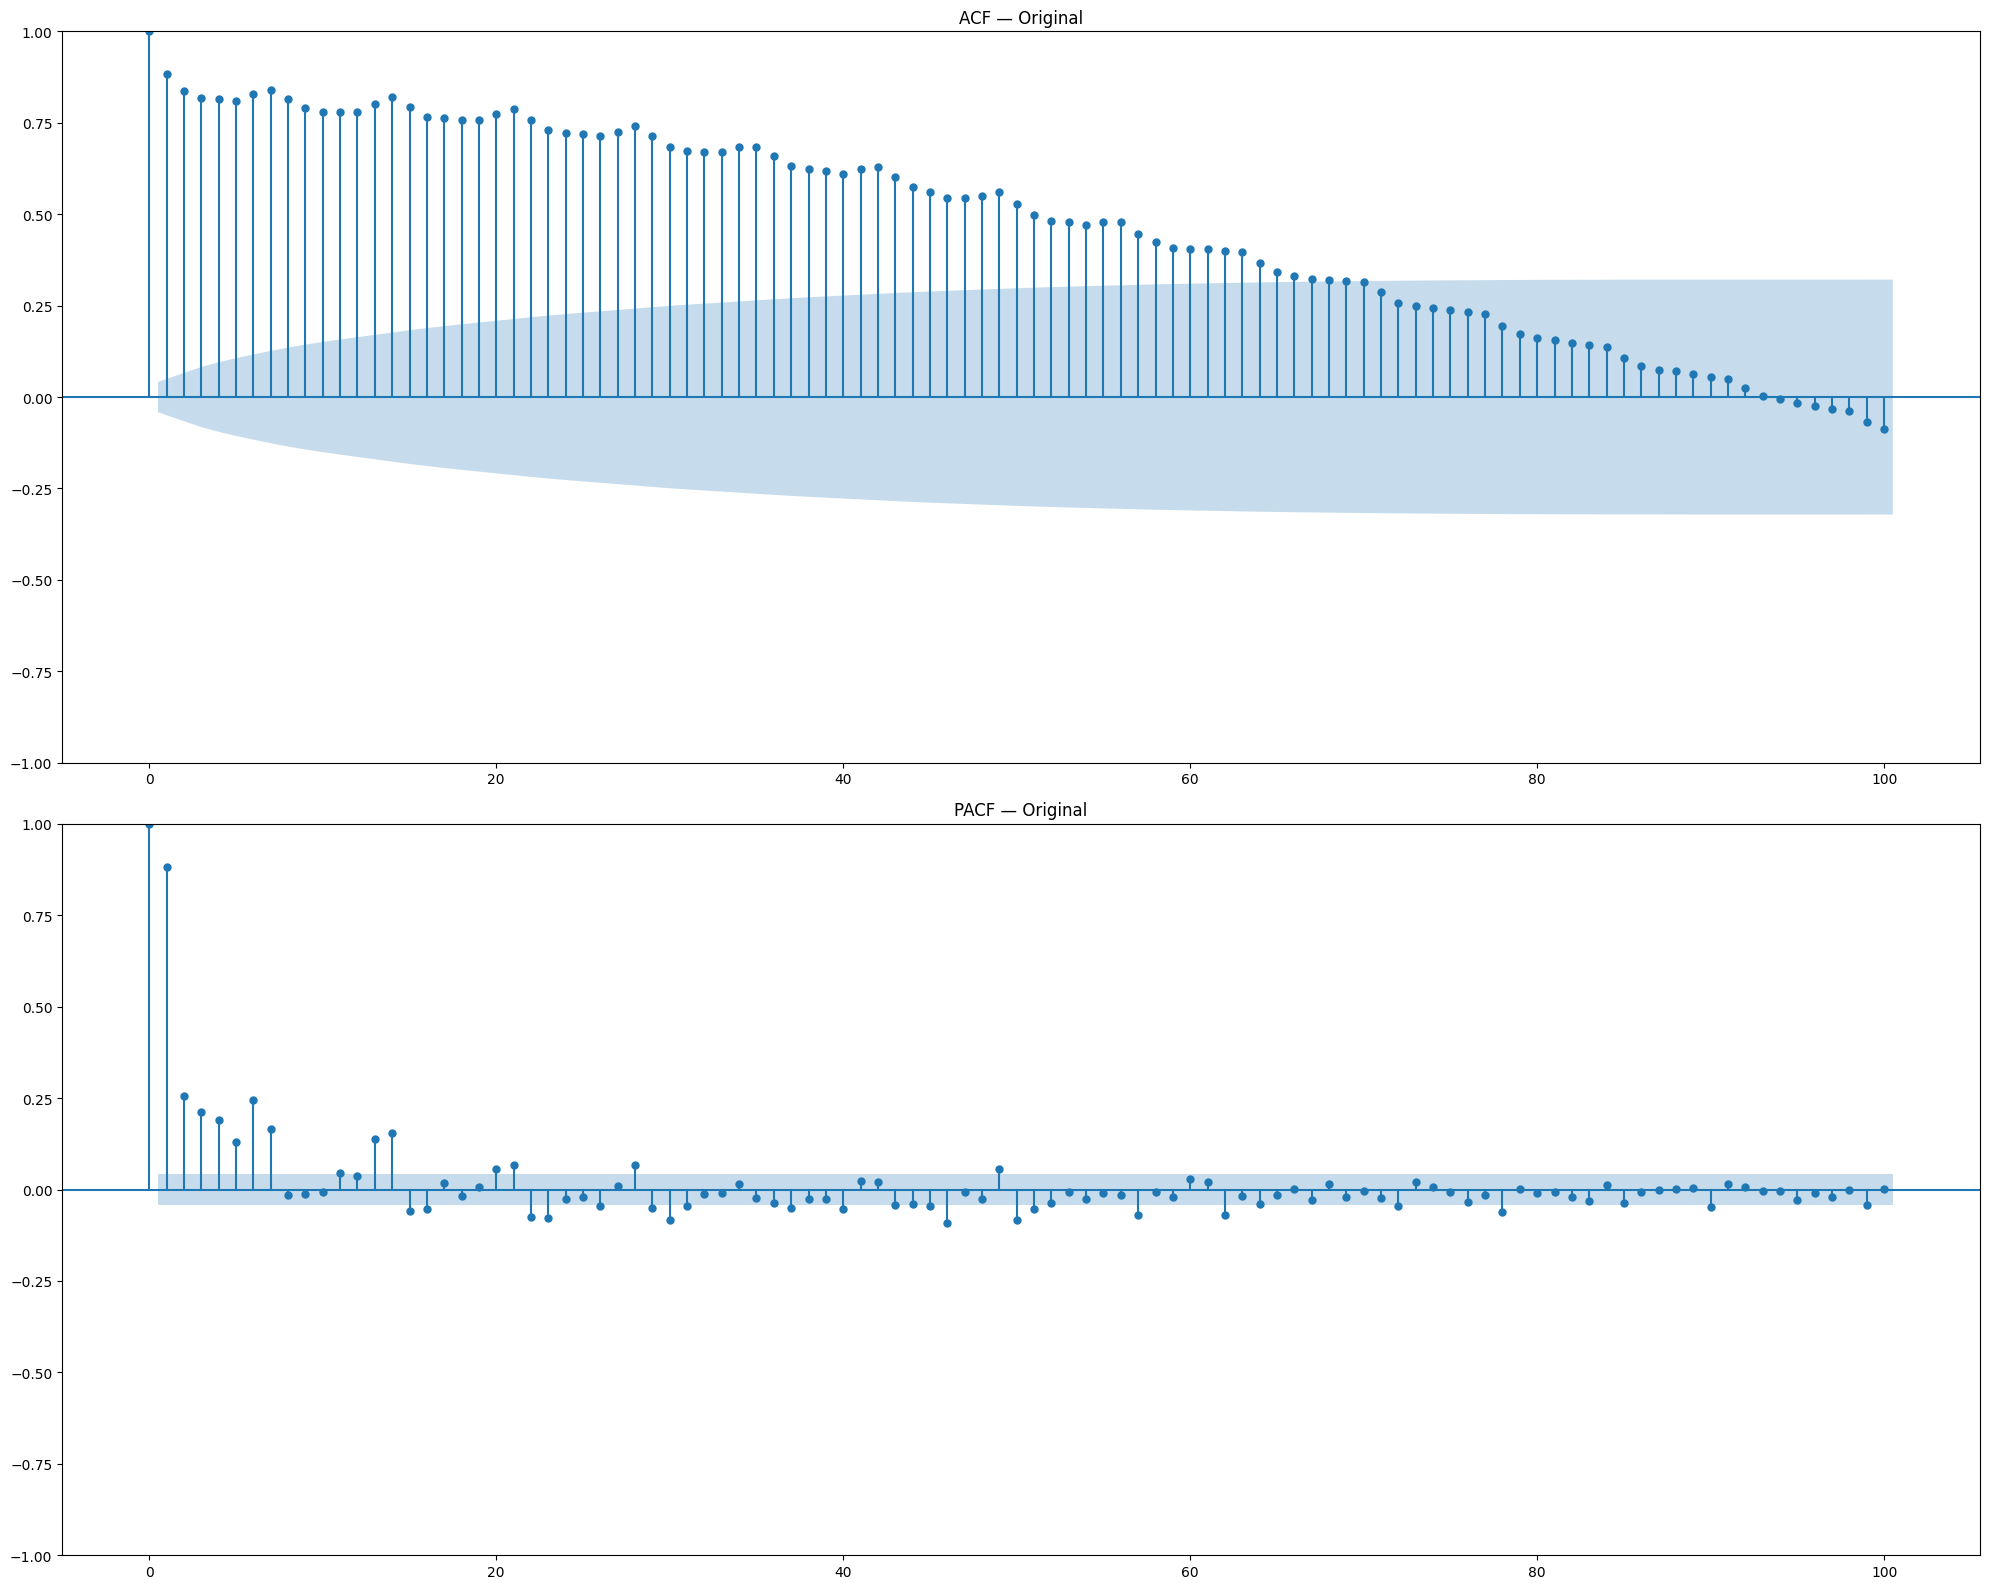

In [24]:
# ACF / PACF — original
LAGS = 100

fig, axes = plt.subplots(2, 1, figsize=(20, 16))
plot_acf( series_orig, lags=LAGS, ax=axes[0], alpha=0.05)
plot_pacf(series_orig, lags=LAGS, ax=axes[1], alpha=0.05, method='ywm')
axes[0].set_title("ACF — Original")
axes[1].set_title("PACF — Original")
plt.tight_layout()
plt.show()


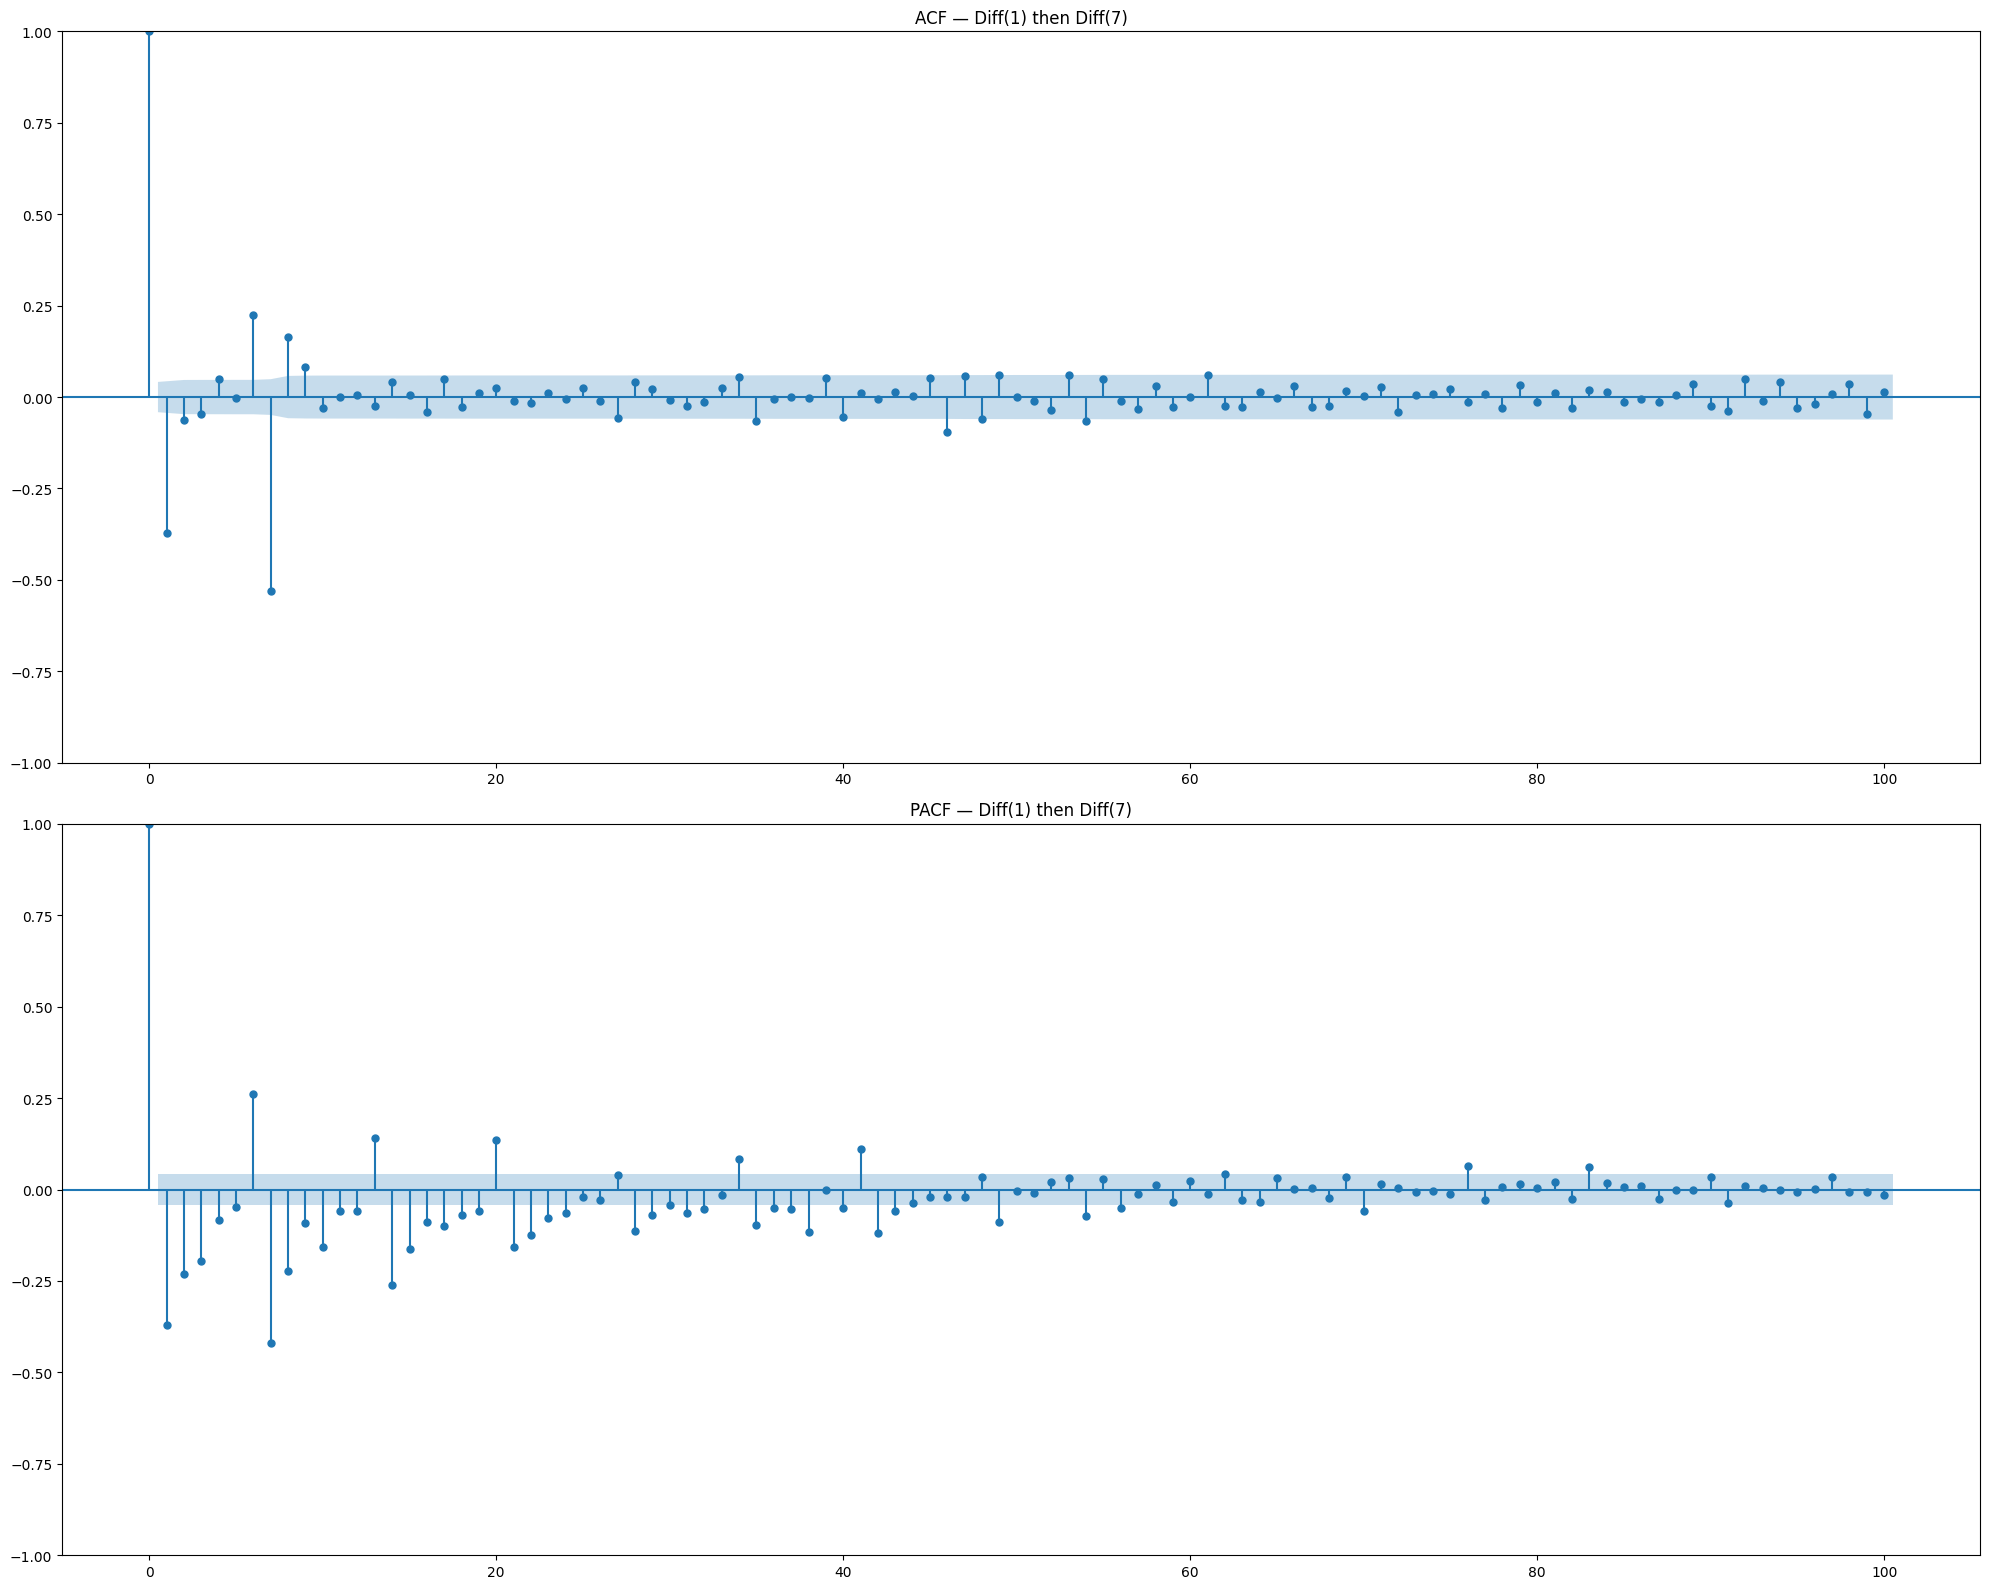

In [25]:
# ACF / PACF — weekly differenced
fig, axes = plt.subplots(2, 1, figsize=(20, 16))
plot_acf( series_diff7, lags=LAGS, ax=axes[0], alpha=0.05)
plot_pacf(series_diff7, lags=LAGS, ax=axes[1], alpha=0.05, method='ywm')
axes[0].set_title("ACF — Diff(1) then Diff(7)")
axes[1].set_title("PACF — Diff(1) then Diff(7)")
plt.tight_layout()
plt.show()


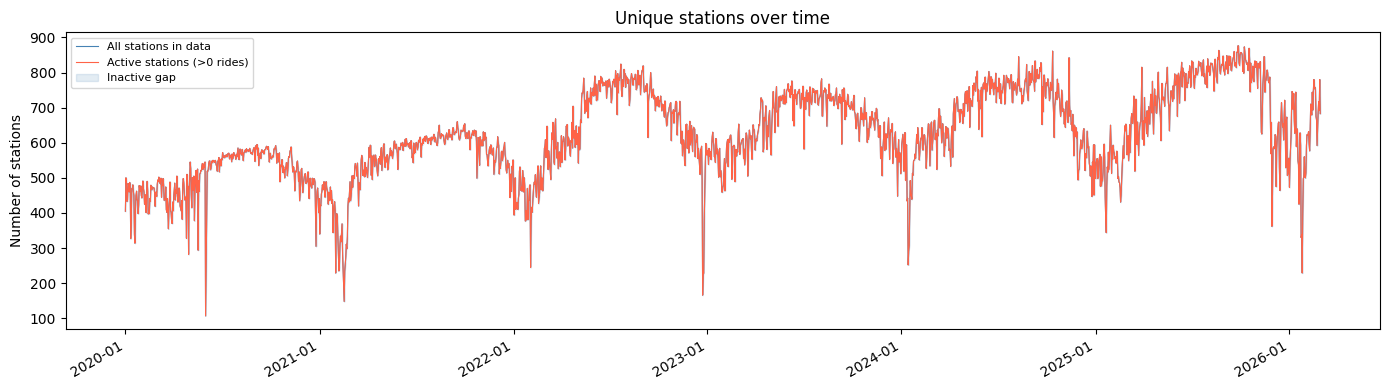

Date range:        2020-01-01 → 2026-02-28
Max stations:      876
Min stations:      107
Max active:        876
Min active:        107


In [26]:
## Station count over time
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])

# unique active stations per day
stn_per_day = (
    station[station['total_rides'] > 0]
    .groupby('date')['start_station_name']
    .nunique()
    .rename('active_stations')
)

# all stations seen per day (including zero-ride days)
stn_per_day_all = (
    station
    .groupby('date')['start_station_name']
    .nunique()
    .rename('all_stations')
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(stn_per_day_all.index, stn_per_day_all.values,
        color='steelblue', linewidth=0.8, label='All stations in data')
ax.plot(stn_per_day.index, stn_per_day.values,
        color='tomato', linewidth=0.8, label='Active stations (>0 rides)')
ax.fill_between(stn_per_day_all.index,
                stn_per_day.reindex(stn_per_day_all.index).fillna(0),
                stn_per_day_all,
                alpha=0.15, color='steelblue', label='Inactive gap')
ax.set_ylabel('Number of stations')
ax.set_title('Unique stations over time')
ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m'))
plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.show()

print(f'Date range:        {stn_per_day_all.index.min().date()} → {stn_per_day_all.index.max().date()}')
print(f'Max stations:      {stn_per_day_all.max()}')
print(f'Min stations:      {stn_per_day_all.min()}')
print(f'Max active:        {stn_per_day.max()}')
print(f'Min active:        {stn_per_day.min()}')
